### Market Structure Multi-Scale Analysis V2

In [ ]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import pywt
import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm

from scipy.stats import spearmanr
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import fisher_exact
from sklearn.metrics import roc_auc_score
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.request_api_v2 import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension
from Modules.fibonacci_retracement import FibonacciRetracement
from Modules.fibonacci_extension import FibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
fred_url = "https://api.stlouisfed.org/fred/series/observations"
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()
# Fibonacciエクステンションをプロットするクラスのインスタンスを作成
fibonacci_extension_v2 = FibonacciExtension() 
# Fibonacciリトレースメントを計算するクラスのインスタンスを作成
fibonacci_retracement = FibonacciRetracement()

In [3]:
# Date range for fetching API s
start = '1950-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
frequency = "d"
aggregation_method = "avg"

In [12]:
def get_fred_timeseries_data(
    observation_start: str,
    observation_end: str,
    series_mapping: dict[str, str] | None = None,
    frequency: str | None = None,
    aggregation_method: str | None = None,
) -> dict[str, pd.DataFrame]:
    observation_start = observation_start
    observation_end = observation_end
    base_fred_params = {
        "api_key": FRED_API_KEY,
        "file_type": "json",
        "observation_start": observation_start,
        "observation_end": observation_end,
        "frequency": frequency or "m",
        "aggregation_method": aggregation_method or "avg",
    }
    fred_dfs = {}
    for series_id, series_name in series_mapping.items():
        fred_params = base_fred_params.copy()
        fred_params["series_id"] = series_id
        fred_res = requests.get(fred_url, params=fred_params)
        fred_df = pd.DataFrame(fred_res.json()["observations"]).assign(**{
            "date": lambda df: pd.to_datetime(df["date"]),
            "value": lambda df: pd.to_numeric(df["value"], errors="coerce"),
            "interest_rate_type": series_name,
        })
        fred_dfs[series_name] = fred_df
        time.sleep(5)
        
    return fred_dfs

In [4]:
def delete_column(df):
    df = df.drop(columns=['realtime_start', 'realtime_end', 'interest_rate_type'])
    return df

#### S&P500(均等加重)時系列を取得

In [5]:
spxew_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^SPXEW",
    market=None,
    series_name="SPXEW"
))
spxew_df.tail()

取得件数: 4988


,value
date,
2026-10-22,8774.019531
2026-10-23,8841.269531
2026-10-26,8772.370117
2026-10-27,8802.639648
2026-10-28,8809.419922


#### S&P500(時価総額加重平均)時系列を取得

In [6]:
sp500_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^GSPC",
    market=None,
    series_name="GSPC"
))
sp500_df.tail()

取得件数: 19358


,value
date,
2026-10-22,7694.620117
2026-10-23,7637.180176
2026-10-26,7639.700195
2026-10-27,7699.470215
2026-10-28,7735.560059


#### Nasdaq100(均等加重)時系列を取得

In [7]:
ndxe_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^NDXE",
    market=None,
    series_name="NDXE"
))
ndxe_df.tail()

取得件数: 5149


,value
date,
2026-10-22,9974.679688
2026-10-23,9893.769531
2026-10-26,9917.309570
2026-10-27,10010.910156
2026-10-28,10064.759766


#### Nasdaq100(時価総額加重平均)時系列を取得

In [8]:
qqq_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^IXIC",
    market=None,
    series_name="IXIC"
))
qqq_df.tail()

取得件数: 14050


,value
date,
2026-10-22,26308.410156
2026-10-23,25893.949219
2026-10-26,26026.869141
2026-10-27,26286.310547
2026-10-28,26541.609375


#### iShares iBoxx $ High Yield Corporate Bond ETF

In [9]:
hyg_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="HYG",
    market=None,
    series_name="HYG"
))
hyg_df.tail()

取得件数: 4920


,value
date,
2026-10-22,76.769997
2026-10-23,76.889999
2026-10-26,77.080002
2026-10-27,77.300003
2026-10-28,77.709999


#### iShares 7-10 Year Treasury Bond ETF (IEF)

In [10]:
ief_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="IEF",
    market=None,
    series_name="IEF"
))
ief_df.tail()

取得件数: 6102


,value
date,
2026-10-22,90.750000
2026-10-23,91.230003
2026-10-26,91.160004
2026-10-27,91.059998
2026-10-28,91.059998


#### Federal Funds Effective Rate (DFF)

In [13]:
dff_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DFF": "federal_funds_effective_rate"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["federal_funds_effective_rate"]
dff_df["date"] = pd.to_datetime(dff_df["date"])
dff_df = dff_df.set_index("date")
dff_df = delete_column(dff_df)
dff_df.head()

,value
date,
1954-07-01,1.13
1954-07-02,1.25
1954-07-03,1.25
1954-07-04,1.25
1954-07-05,0.88


#### Market Yield on U.S. Treasury Securities at 2-Year Constant Maturity, Quoted on an Investment Basis (DGS2)

In [14]:
dgs2_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DGS2": "two_year_treasury_yield"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["two_year_treasury_yield"]
dgs2_df["date"] = pd.to_datetime(dgs2_df["date"])
dgs2_df = dgs2_df.set_index("date")
dgs2_df = delete_column(dgs2_df)
dgs2_df.head()

,value
date,
1976-06-01,7.26
1976-06-02,7.23
1976-06-03,7.22
1976-06-04,7.12
1976-06-07,7.09


#### Market Yield on U.S. Treasury Securities at 10-Year Constant Maturity, Quoted on an Investment Basis (DGS10)

In [15]:
dgs10_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DGS10": "ten_year_treasury_yield"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["ten_year_treasury_yield"]
dgs10_df["date"] = pd.to_datetime(dgs10_df["date"])
dgs10_df = dgs10_df.set_index("date")
dgs10_df = delete_column(dgs10_df)
dgs10_df.head()

,value
date,
1962-01-02,4.06
1962-01-03,4.03
1962-01-04,3.99
1962-01-05,4.02
1962-01-08,4.03


#### U.S. Dollars to Australian Dollar Spot Exchange Rate (DEXUSAL)

In [16]:
dxy_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DEXUSAL": "DXY"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["DXY"]
dxy_df["date"] = pd.to_datetime(dxy_df["date"])
dxy_df = dxy_df.set_index("date")
dxy_df = delete_column(dxy_df)
dxy_df.tail()

,value
date,
2026-10-19,0.6981
2026-10-20,0.7004
2026-10-21,0.7026
2026-10-22,0.7020
2026-10-23,0.7037


#### Market Yield on U.S. Treasury Securities at 10-Year Constant Maturity, Quoted on an Investment Basis, Inflation-Indexed (DFII10)

In [17]:
real_yield_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DFII10": "real_10y"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["real_10y"]
real_yield_df["date"] = pd.to_datetime(real_yield_df["date"])
real_yield_df = real_yield_df.set_index("date")
real_yield_df = delete_column(real_yield_df)
real_yield_df.tail()

,value
date,
2026-10-21,2.76
2026-10-22,2.64
2026-10-23,2.66
2026-10-26,2.66
2026-10-27,2.64


#### ICE BofA US High Yield Index Option-Adjusted Spread (BAMLH0A0HYM2)

In [18]:
credit_spread_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLH0A0HYM2": "credit_spread"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["credit_spread"]
credit_spread_df["date"] = pd.to_datetime(credit_spread_df["date"])
credit_spread_df = credit_spread_df.set_index("date")
credit_spread_df = delete_column(credit_spread_df)
credit_spread_df.tail()

,value
date,
2026-10-21,3.27
2026-10-22,3.40
2026-10-23,3.38
2026-10-26,3.30
2026-10-27,3.18


#### ICE BofA AAA US Corporate Index Option-Adjusted Spread (BAMLC0A1CAAA)

In [19]:
aaa_oas_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLC0A1CAAA": "AAA_OAS"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["AAA_OAS"]
aaa_oas_df["date"] = pd.to_datetime(aaa_oas_df["date"])
aaa_oas_df = aaa_oas_df.set_index("date")
aaa_oas_df = delete_column(aaa_oas_df)
aaa_oas_df.tail()

,value
date,
2026-10-21,0.42
2026-10-22,0.42
2026-10-23,0.44
2026-10-26,0.43
2026-10-27,0.42


#### ICE BofA BBB US Corporate Index Option-Adjusted Spread (BAMLC0A4CBBB)

In [20]:
bbb_oas_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLC0A4CBBB": "BBB_OAS"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["BBB_OAS"]
bbb_oas_df["date"] = pd.to_datetime(bbb_oas_df["date"])
bbb_oas_df = bbb_oas_df.set_index("date")
bbb_oas_df = delete_column(bbb_oas_df)
bbb_oas_df.tail()

,value
date,
2026-10-21,1.09
2026-10-22,1.11
2026-10-23,1.13
2026-10-26,1.12
2026-10-27,1.09


#### Federal Funds Effective Rate (FEDFUNDS)

In [21]:
ffer_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"FEDFUNDS": "ff_rate"},
    frequency='m',
    aggregation_method=aggregation_method
)["ff_rate"]
ffer_df["date"] = pd.to_datetime(ffer_df["date"])
ffer_df = ffer_df.set_index("date")
ffer_df = delete_column(ffer_df)
ffer_df.tail()

,value
date,
2026-05-01,3.63
2026-06-01,3.63
2026-07-01,3.63
2026-08-01,3.63
2026-09-01,3.75


#### データ統合

In [22]:
# ============================================================
# データ統合
# ============================================================
# 各データを共通フォーマットへ変換
df_list = [
    spxew_df.rename(columns={'value': "SPXEW"}),
    sp500_df.rename(columns={'value': "GSPC"}),
    ndxe_df.rename(columns={'value': "NDXE"}),
    qqq_df.rename(columns={'value': "IXIC"}),
    hyg_df.rename(columns={'value': "HYG"}),
    ief_df.rename(columns={'value': "IEF"}),
    dff_df.rename(columns={'value': "DFF"}),
    dgs2_df.rename(columns={'value': "DGS2"}),
    dgs10_df.rename(columns={'value': "DGS10"}),
    dxy_df.rename(columns={'value': "DXY"}),
    real_yield_df.rename(columns={'value': "DFII10"}),
    credit_spread_df.rename(columns={'value': "BAMLH0A0HYM2"}),
    aaa_oas_df.rename(columns={'value': "BAMLC0A1CAAA"}),
    bbb_oas_df.rename(columns={'value': "BAMLC0A4CBBB"}),
    ffer_df.rename(columns={'value': "FEDFUNDS"}),
]
# 日付で外部結合
market_df = pd.concat(df_list, axis=1, join="outer")
# 日付順にソート
market_df = market_df.sort_index()
# 重複日付除去
market_df = market_df[~market_df.index.duplicated(keep="first")]
# 欠損補完
market_df = market_df.ffill()
# 全列欠損行は削除
market_df = market_df.dropna(how="all")
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"data_integration_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = market_df.copy()
df.to_csv(output_path)
# 確認
print("=" * 60)
print("Market Data Shape")
print(market_df.shape)
print("\nColumns")
print(market_df.columns.tolist())
print("\nHead")
display(market_df.head())
print("\nTail")
display(market_df.tail())

Market Data Shape
(27572, 15)

Columns
['SPXEW', 'GSPC', 'NDXE', 'IXIC', 'HYG', 'IEF', 'DFF', 'DGS2', 'DGS10', 'DXY', 'DFII10', 'BAMLH0A0HYM2', 'BAMLC0A1CAAA', 'BAMLC0A4CBBB', 'FEDFUNDS']

Head


/tmp/ipykernel_26/2123539230.py:23: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  market_df = pd.concat(df_list, axis=1, join="outer")


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,DFII10,BAMLH0A0HYM2,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS
date,,,,,,,,,,,,,,,
1949-11-17,NaN,15.960000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-18,NaN,16.139999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-21,NaN,16.070000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-22,NaN,16.150000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-23,NaN,16.190001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Tail


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,DFII10,BAMLH0A0HYM2,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS
date,,,,,,,,,,,,,,,
2026-10-24,8841.269531,7637.180176,9893.769531,25893.949219,76.889999,91.230003,3.88,4.69,5.00,0.7037,2.66,3.38,0.44,1.13,3.75
2026-10-25,8841.269531,7637.180176,9893.769531,25893.949219,76.889999,91.230003,3.88,4.69,5.00,0.7037,2.66,3.38,0.44,1.13,3.75
2026-10-26,8772.370117,7639.700195,9917.309570,26026.869141,77.080002,91.160004,3.88,4.68,5.00,0.7037,2.66,3.30,0.43,1.12,3.75
2026-10-27,8802.639648,7699.470215,10010.910156,26286.310547,77.300003,91.059998,3.88,4.70,4.99,0.7037,2.64,3.18,0.42,1.09,3.75
2026-10-28,8809.419922,7735.560059,10064.759766,26541.609375,77.709999,91.059998,3.88,4.70,4.99,0.7037,2.64,3.18,0.42,1.09,3.75


#### 1. Prepare Target Series

S&P500 log return

In [33]:
# 研究用データフレームを作成
research_df = market_df.copy()
# 研究用データフレームを作成
research_df.index = pd.to_datetime(research_df.index)
# 必要な列のみ抽出し欠損値を削除
research_df = research_df[["GSPC", "DGS10", "BAMLH0A0HYM2", "BAMLC0A4CBBB", "HYG", "IEF"]].dropna()
# GSPCの対数リターンを計算
research_df["GSPC_LOG_RET"] = (np.log(research_df["GSPC"]).diff())
# 欠損値を削除
research_df = research_df.dropna()
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"1_research_df_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_df.copy()
df.to_csv(output_path)
print("saved:", output_path)
research_df.head()

saved: /workspace/data/1_research_df_2026-10-29.csv


,GSPC,DGS10,BAMLH0A0HYM2,BAMLC0A4CBBB,HYG,IEF,GSPC_LOG_RET
date,,,,,,,
2023-10-31,4171.330078,4.88,4.42,1.62,60.647275,80.347039,0.007686
2023-11-01,4201.270020,4.77,4.47,1.63,60.863783,80.364706,0.007152
2023-11-02,4268.259766,4.67,4.15,1.59,61.747972,81.674185,0.015819
2023-11-03,4334.229980,4.57,4.04,1.58,62.438447,82.553214,0.015338
2023-11-04,4334.229980,4.57,4.04,1.58,62.438447,82.553214,0.000000


#### 2. Wavelet Decomposition

In [34]:
# GSPCの対数リターンに対してSWTを適用し、マルチスケールの詳細係数を計算
signal = research_df["GSPC_LOG_RET"].values
# 信号の長さを取得
n = len(signal)
# 信号の長さを2の累乗に揃えるためのパワーを計算
power = int(np.floor(np.log2(n)))
# 使える信号の長さを計算
usable_length = 2**power
# 使える信号の長さに合わせてデータフレームを切り取る
research_df = research_df.iloc[-usable_length:].copy()
# 切り取ったデータフレームから信号を再取得
signal = research_df["GSPC_LOG_RET"].values
# SWTの最大レベルを設定
MAX_LEVEL = 6
# SWTを適用して詳細係数を計算
coeffs = pywt.swt(signal, wavelet="db4", level=MAX_LEVEL,)
# 各レベルの詳細係数をデータフレームに追加
for level_idx, (_, detail) in enumerate(coeffs, start=1):
    # 現在のレベルを計算
    level = MAX_LEVEL - level_idx + 1
    # データフレームに追加する列名を作成
    column_name = f"GSPC_D{level}"
    research_df[column_name] = detail
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"2_wavelet_decomposition_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_df.copy()
df.to_csv(output_path)
print("saved:", output_path)
# データフレームの末尾を表示
research_df.tail()


saved: /workspace/data/2_wavelet_decomposition_2026-10-29.csv


,GSPC,DGS10,BAMLH0A0HYM2,BAMLC0A4CBBB,HYG,IEF,GSPC_LOG_RET,GSPC_D6,GSPC_D5,GSPC_D4,GSPC_D3,GSPC_D2,GSPC_D1
date,,,,,,,,,,,,,
2026-10-24,7637.180176,5.00,3.38,1.13,76.889999,91.230003,0.000000,0.000188,0.002161,-0.007271,0.004272,0.000916,0.004154
2026-10-25,7637.180176,5.00,3.38,1.13,76.889999,91.230003,0.000000,0.000174,0.001485,-0.006590,-0.000668,-0.000707,-0.003144
2026-10-26,7639.700195,5.00,3.30,1.12,77.080002,91.160004,0.000330,0.000142,0.000663,-0.004405,-0.005318,-0.000365,0.001886
2026-10-27,7699.470215,4.99,3.18,1.09,77.300003,91.059998,0.007793,0.000072,0.000103,-0.001360,-0.008732,-0.002441,-0.002613
2026-10-28,7735.560059,4.99,3.18,1.09,77.709999,91.059998,0.004676,0.000050,0.000053,0.000864,-0.011805,-0.004715,0.003350


#### 3. Lag Correlation Analysis

DGS10(t) vs GSPC_Dk(t+lag)

In [35]:

# ラグの範囲を設定
lags = np.arange(0, 1001, 20)
results = []
# 各レベルの詳細係数に対してラグ相関を計算
for level in range(1, 7):
    # 対象の列名を作成
    target_col = f"GSPC_D{level}"
    # 各ラグに対して相関を計算
    for lag in lags:
        tmp = pd.DataFrame({
            "x": research_df["DGS10"],
            "y": research_df[target_col]
            .shift(-lag)
        }).dropna()
        # データが十分にあるか確認
        if len(tmp) < 500:
            continue
        # 相関を計算
        corr = tmp["x"].corr(tmp["y"])
        # 結果を保存
        results.append({
            "target": target_col,
            "lag": lag,
            "corr": corr,
            "abs_corr": abs(corr),
            "n": len(tmp)
        })
# ラグ相関の結果をデータフレームに変換
lag_corr_df = pd.DataFrame(
    results
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"3_lag_correlation_analysis_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = lag_corr_df.copy()
df.to_csv(output_path)
print("saved:", output_path)
# ラグ相関の結果を表示
lag_corr_df.head()

saved: /workspace/data/3_lag_correlation_analysis_2026-10-29.csv


,target,lag,corr,abs_corr,n
0,GSPC_D1,0,0.003659,0.003659,1024
1,GSPC_D1,20,-0.000179,0.000179,1004
2,GSPC_D1,40,-0.005309,0.005309,984
3,GSPC_D1,60,0.005783,0.005783,964
4,GSPC_D1,80,-0.000038,0.000038,944


#### 4. Lag × Scale Heatmap

saved: /workspace/data/figures/4_DGS10_vs_Wavelet_Scale_Lag_Correlation_1950-01-01_2026-10-29.png


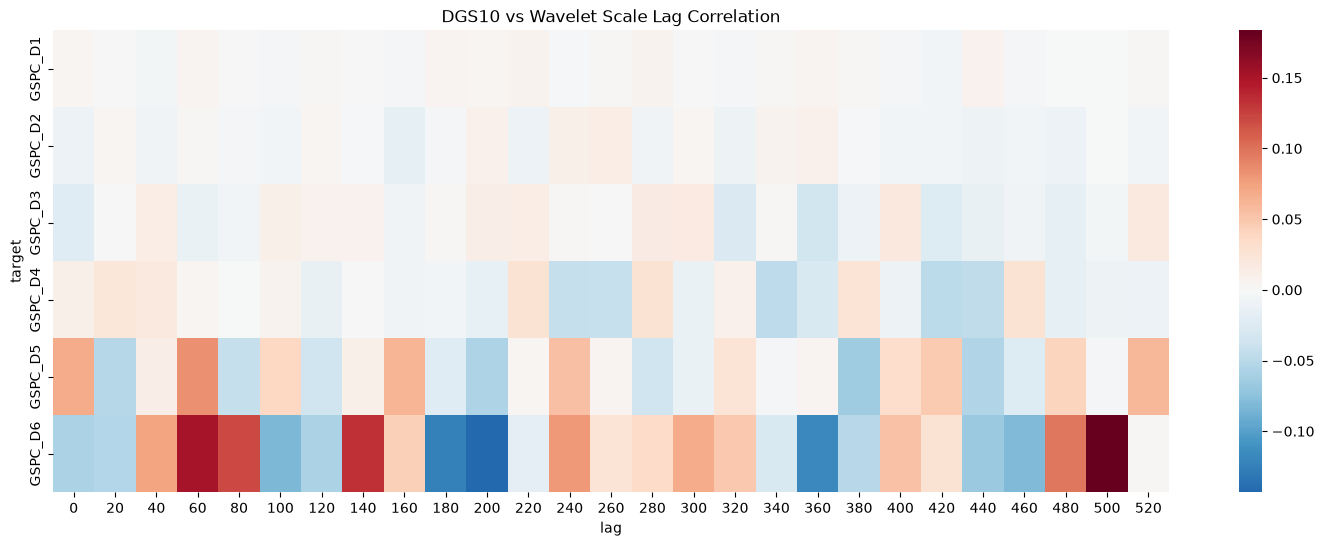

In [36]:
# ラグ相関のヒートマップを作成
heatmap_df = (
    lag_corr_df
    .pivot(
        index="target",
        columns="lag",
        values="corr"
    )
)
plt.figure(figsize=(18, 6))
sns.heatmap(
    heatmap_df,
    cmap="RdBu_r",
    center=0
)
plt.title("DGS10 vs Wavelet Scale Lag Correlation")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"4_DGS10_vs_Wavelet_Scale_Lag_Correlation_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)

plt.show()

#### 5. Peak Lag Detection

In [37]:
peak_corr_df = (
    lag_corr_df.sort_values("abs_corr",ascending=False)
    .groupby("target", as_index=False).first()
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"5_peak_lag_detection_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
peak_corr_df.to_csv(output_path)
print("saved:", output_path)
# ピーク相関のデータフレームを表示
peak_corr_df.tail()

saved: /workspace/data/5_peak_lag_detection_2026-10-29.csv


,target,lag,corr,abs_corr,n
1,GSPC_D2,160,-0.016298,0.016298,864
2,GSPC_D3,360,-0.034950,0.034950,664
3,GSPC_D4,420,-0.050083,0.050083,604
4,GSPC_D5,60,0.082828,0.082828,964
5,GSPC_D6,500,0.183445,0.183445,524


#### 6. Candidate Variables

- Credit Market
- Bond Market

In [38]:
candidate_features = [
    "BAMLH0A0HYM2",   # HY OAS
    "BAMLC0A4CBBB",   # BBB OAS
    "HYG",            # High Yield ETF
    "IEF",            # 7-10Y Treasury ETF
]
research_df.keys()

Index(['GSPC', 'DGS10', 'BAMLH0A0HYM2', 'BAMLC0A4CBBB', 'HYG', 'IEF',
       'GSPC_LOG_RET', 'GSPC_D6', 'GSPC_D5', 'GSPC_D4', 'GSPC_D3', 'GSPC_D2',
       'GSPC_D1'],
      dtype='str')

#### 7. Lag Correlation Analysis

X(t) vs GSPC_Dk(t + lag)

In [39]:
# ラグ相関分析の実行
lags = np.arange(0, 1001, 20)
results = []
# 各特徴量と各ターゲット列のラグ相関を計算する
for feature in candidate_features:
    # 特徴量の時系列データを取得
    feature_series = research_df[feature]
    # 各ターゲット列のラグ相関を計算する
    for level in range(1, 7):
        # ターゲット列の名前を作成
        target_col = (f"GSPC_D{level}")
        # 各ラグで相関を計算する
        for lag in lags:
            # 特徴量とターゲット列のデータを作成
            tmp = pd.DataFrame(
                {
                    "x": feature_series,
                    "y": research_df[target_col].shift(-lag),
                }
            ).dropna()
            # 
            if len(tmp) < 500:
                continue
            # データが十分でない場合はスキップ
            corr = (tmp["x"].corr(tmp["y"]))
            # 計算結果を保存する
            results.append(
                {
                    "feature": feature,
                    "target": target_col,
                    "lag": lag,
                    "corr": corr,
                    "abs_corr": abs(corr),
                    "n": len(tmp),
                }
            )
# ラグ相関の結果をデータフレームに変換
lag_corr_df = pd.DataFrame(results)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"7_lag_correlation_analysis_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
lag_corr_df.to_csv(output_path)
print("saved:", output_path)
# ラグ相関の結果を表示
lag_corr_df.head()

saved: /workspace/data/7_lag_correlation_analysis_2026-10-29.csv


,feature,target,lag,corr,abs_corr,n
0,BAMLH0A0HYM2,GSPC_D1,0,-0.028038,0.028038,1024
1,BAMLH0A0HYM2,GSPC_D1,20,0.004754,0.004754,1004
2,BAMLH0A0HYM2,GSPC_D1,40,0.004671,0.004671,984
3,BAMLH0A0HYM2,GSPC_D1,60,0.000005,0.000005,964
4,BAMLH0A0HYM2,GSPC_D1,80,-0.002823,0.002823,944


#### 8. Peak Lag Detection

Maximum Absolute Correlation

In [40]:
# ピークラグ相関を抽出し、絶対相関の降順でソート
peak_corr_df = (
    lag_corr_df
    .sort_values("abs_corr", ascending=False,)
    .groupby(["feature", "target"], as_index=False,).first()
)
# 絶対相関の降順でソートしたピークラグ相関を取得
peak_corr_df = (
    peak_corr_df
    .sort_values("abs_corr", ascending=False,)
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"8_peak_lag_detection_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
peak_corr_df.to_csv(output_path)
print("saved:", output_path)
# ピークラグ相関の上位30件を表示
peak_corr_df.head(30)

saved: /workspace/data/8_peak_lag_detection_2026-10-29.csv


,feature,target,lag,corr,abs_corr,n
11,BAMLH0A0HYM2,GSPC_D6,380,-0.326213,0.326213,644
5,BAMLC0A4CBBB,GSPC_D6,380,-0.230239,0.230239,644
23,IEF,GSPC_D6,460,0.186317,0.186317,564
17,HYG,GSPC_D6,460,0.168946,0.168946,564
10,BAMLH0A0HYM2,GSPC_D5,480,-0.148209,0.148209,544
4,BAMLC0A4CBBB,GSPC_D5,480,-0.125195,0.125195,544
9,BAMLH0A0HYM2,GSPC_D4,480,-0.098593,0.098593,544
3,BAMLC0A4CBBB,GSPC_D4,480,-0.092686,0.092686,544
22,IEF,GSPC_D5,460,0.085581,0.085581,564
16,HYG,GSPC_D5,480,0.052432,0.052432,544


#### 9. Peak Correlation Heatmap

saved: /workspace/data/figures/9_peak_lag_correlation_1950-01-01_2026-10-29.png


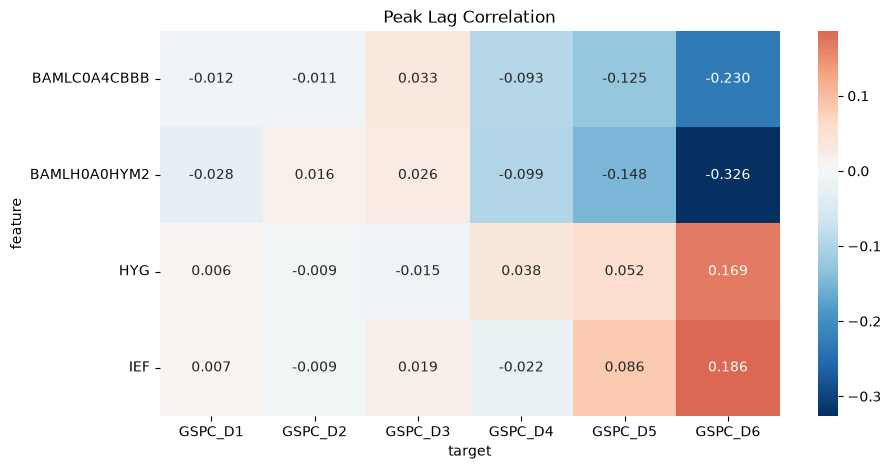

In [41]:
# ピークラグ相関のヒートマップを作成
heatmap_corr = (
    peak_corr_df
    .pivot(
        index="feature",
        columns="target",
        values="corr",
    )
)
plt.figure(figsize=(10, 5))
sns.heatmap(
    heatmap_corr,
    annot=True,
    fmt=".3f",
    center=0,
    cmap="RdBu_r",
)
plt.title("Peak Lag Correlation")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"9_peak_lag_correlation_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# ヒートマップの保存完了のメッセージを表示
print("saved:", output_path)
# ヒートマップを表示
plt.show()

#### 10. Peak Lag Location

At which lag does the strongest relationship occur?

saved: /workspace/data/figures/10_peak_lag_trading_days_1950-01-01_2026-10-29.png


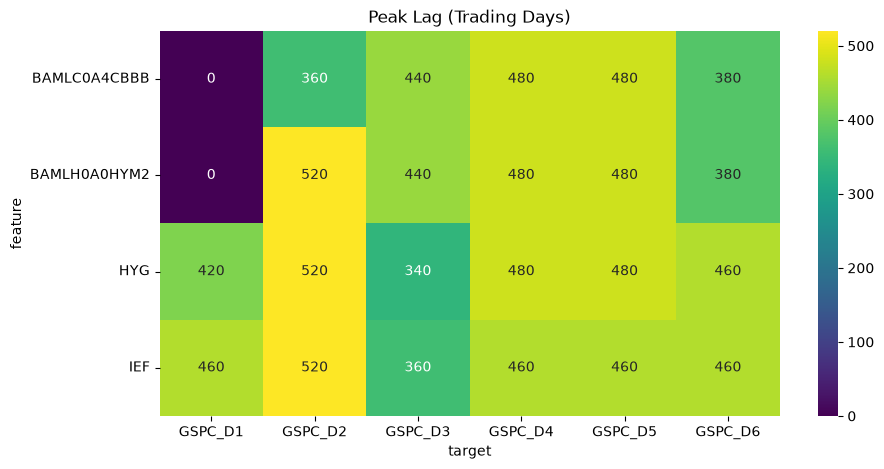

In [42]:
# ピークラグのヒートマップを作成
heatmap_lag = (
    peak_corr_df
    .pivot(
        index="feature",
        columns="target",
        values="lag",
    )
)
plt.figure(figsize=(10, 5))
sns.heatmap(
    heatmap_lag,
    annot=True,
    fmt=".0f",
    cmap="viridis",
)
plt.title("Peak Lag (Trading Days)")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"10_peak_lag_trading_days_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# ヒートマップの保存完了のメッセージを表示
print("saved:", output_path)
# ヒートマップを表示
plt.show()

#### 11. Detailed Lag Curve

Long-wave component only

saved: /workspace/data/figures/11_Detailed_Lag_Curve_1950-01-01_2026-10-29.png


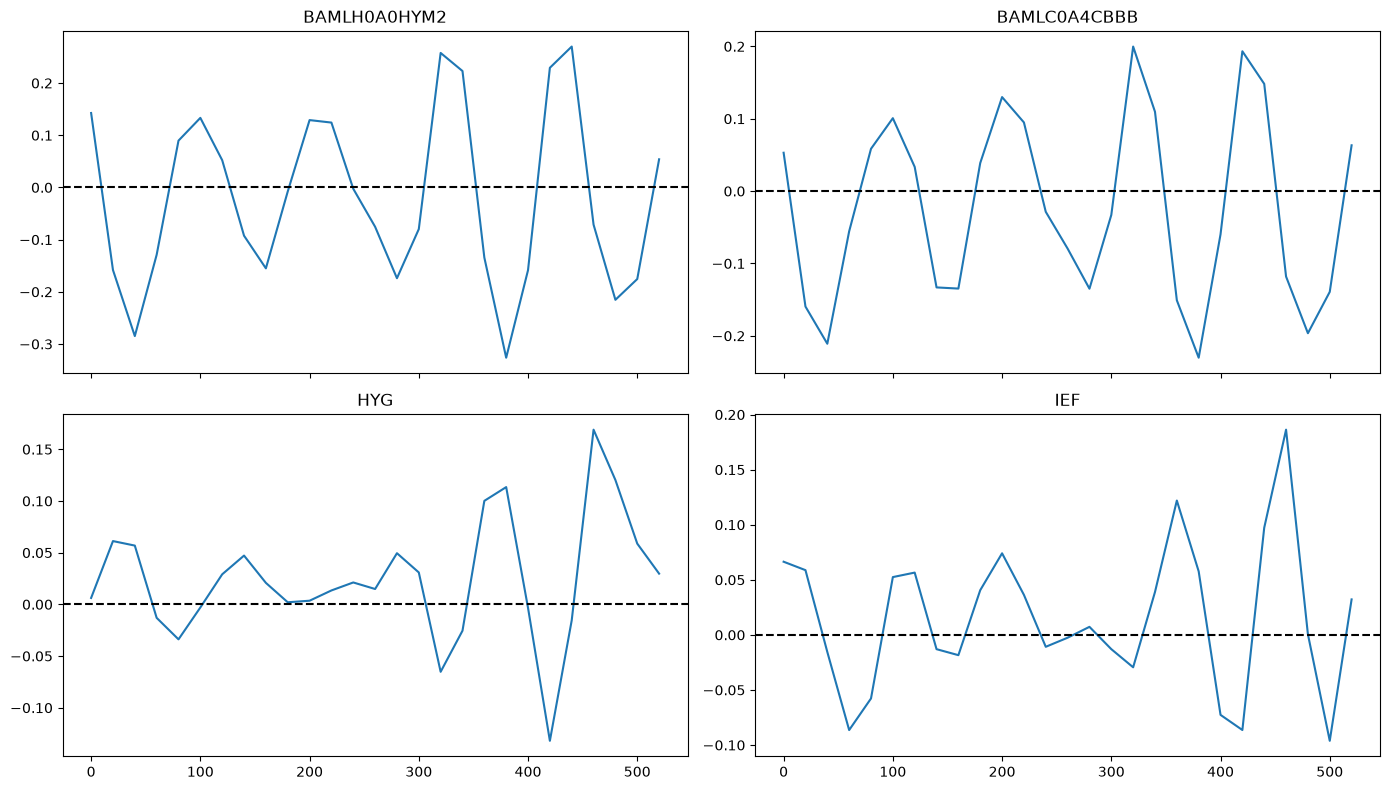

In [43]:
# ラグ相関のプロットを作成
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True,)
axes = axes.flatten()
# 各特徴量ごとにラグ相関をプロット
for ax, feature in zip(axes, candidate_features,):
    # 対象の特徴量とターゲットに絞り込む
    tmp = lag_corr_df[
        (lag_corr_df["feature"] == feature)
        &
        (lag_corr_df["target"] == "GSPC_D6")
    ]
    ax.plot(tmp["lag"], tmp["corr"],)
    ax.axhline(0, color="black", linestyle="--",)
    ax.set_title(feature)
# グラフのレイアウトを調整して表示
plt.tight_layout()
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"11_Detailed_Lag_Curve_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# ヒートマップの保存完了のメッセージを表示
print("saved:", output_path)
# グラフを表示
plt.show()


#### 12. Autocorrelation of GSPC Wavelet Components

GSPC_D6 の周期性および自己相関構造を確認する。

saved: /workspace/data/figures/12_Autocorrelation_of_GSPC_Wavelet_Components_1950-01-01_2026-10-29.png


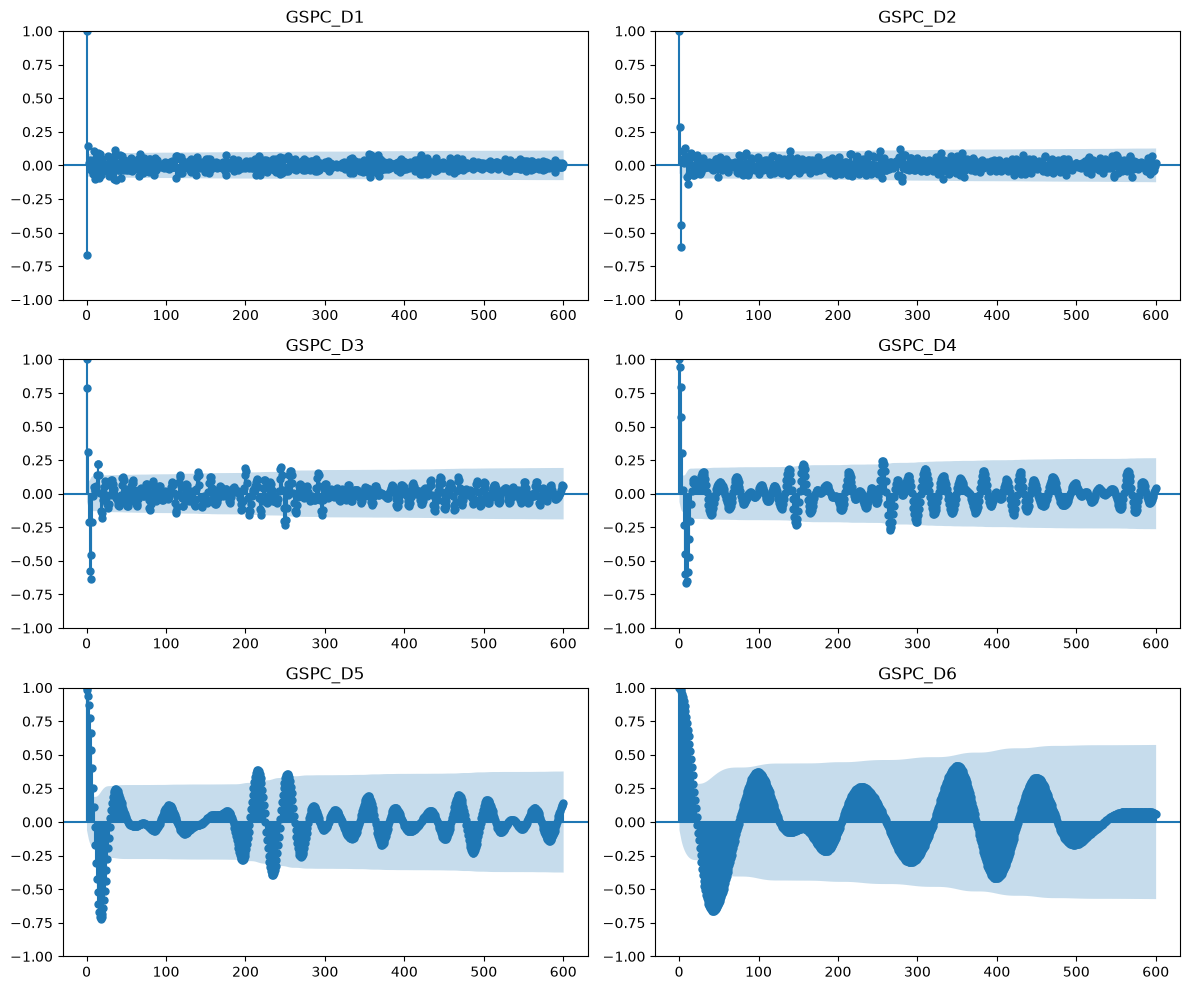

In [44]:
# Plot ACF for GSPC_D1 to GSPC_D6
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
# Create subplots for ACF plots
axes = axes.flatten()
# Loop through GSPC_D1 to GSPC_D6 and plot their ACFs
for i in range(1, 7):
    # Plot ACF for the current GSPC_D column
    plot_acf(
        research_df[f"GSPC_D{i}"].dropna(),
        lags=600,
        ax=axes[i - 1]
    )
    # Set the title for the current subplot
    axes[i - 1].set_title(
        f"GSPC_D{i}"
    )
# Adjust layout to prevent overlap of subplot titles and axes labels
plt.tight_layout()
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"12_Autocorrelation_of_GSPC_Wavelet_Components_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# ヒートマップの保存完了のメッセージを表示
print("saved:", output_path)
# Show the ACF plots
plt.show()

#### 13. FFT of GSPC Wavelet Components

Wavelet成分自身がどの周期を持つか確認する。

saved: /workspace/data/figures/13_FFT_of_GSPC_Wavelet_Components_1950-01-01_2026-10-29.png


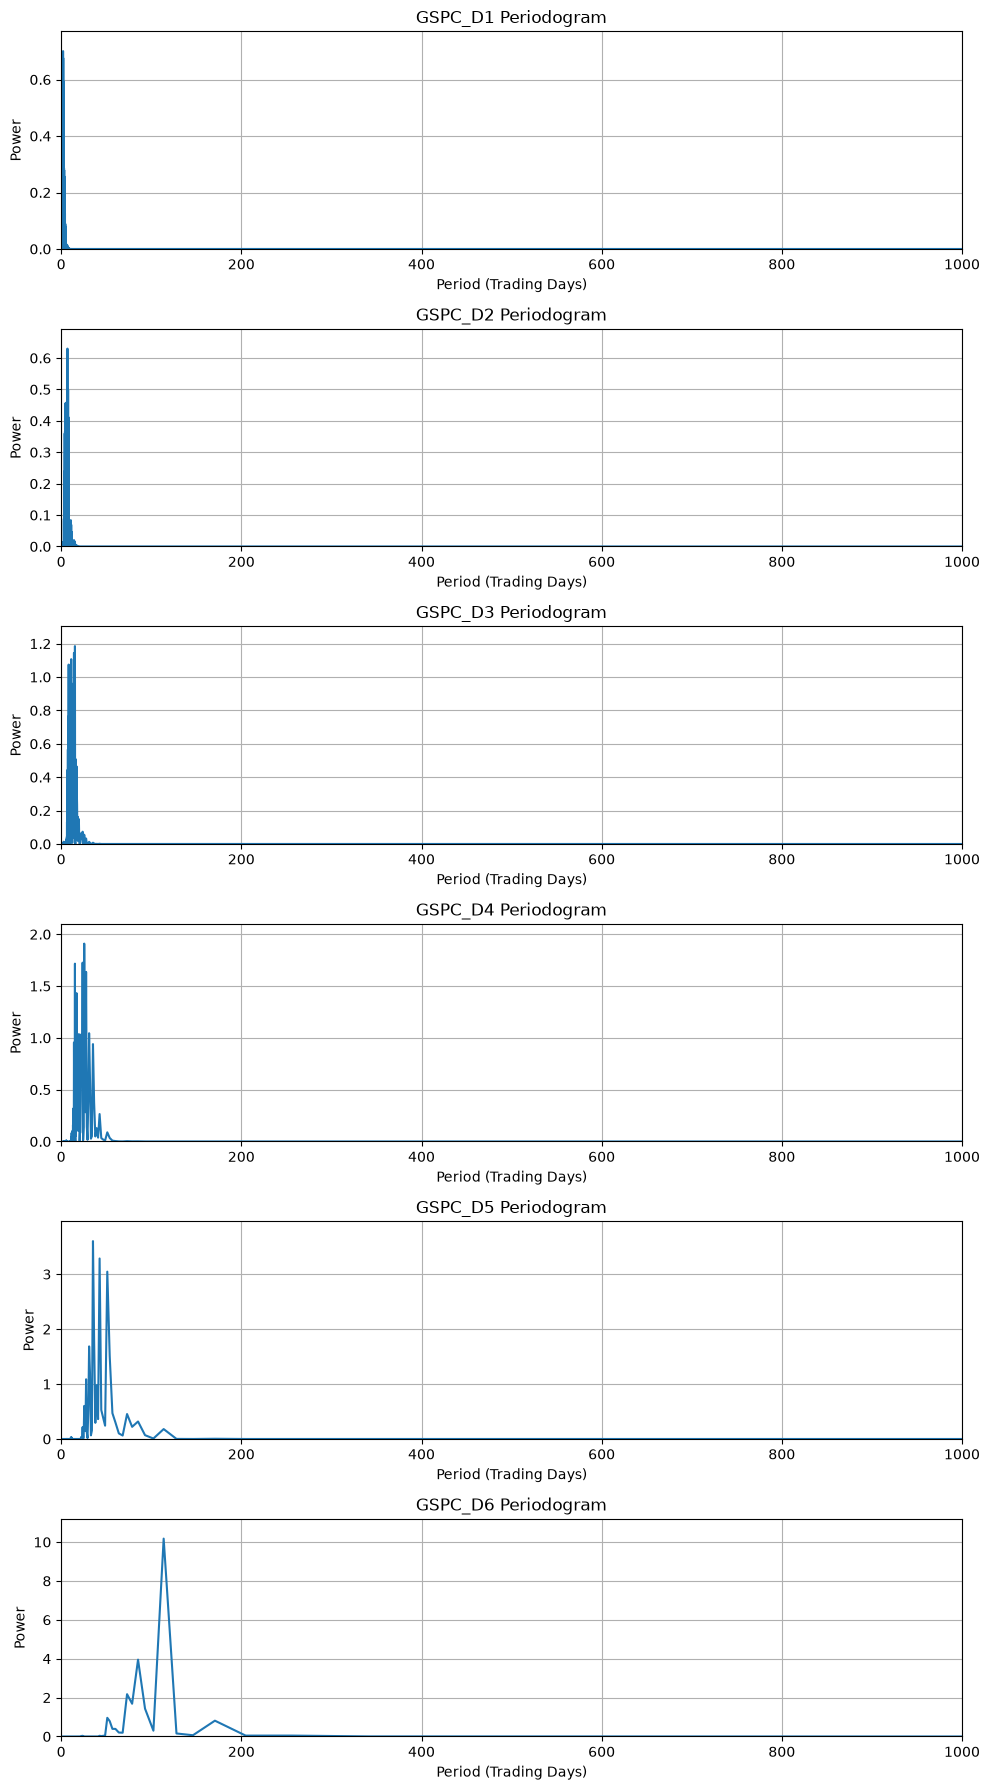

In [47]:
# 6つのサブプロットを持つ1つのFigureを作成
fig, axes = plt.subplots(6, 1, figsize=(10, 18))
# 各GSPC_D列のピリオドグラムをサブプロットに描画する
for i in range(1, 7):
    signal = research_df[f"GSPC_D{i}"].dropna().values
    fft = np.fft.rfft(signal)
    power = np.abs(fft) ** 2
    freq = np.fft.rfftfreq(len(signal), d=1)
    # 周期を計算するために周波数の最初の要素を除去する
    period = 1 / freq[1:]
    power = power[1:]
    # i番目のサブプロットを指定
    ax = axes[i-1]
    ax.plot(period, power)
    ax.set_xlim(0, 1000)
    ax.set_ylim(0, max(power) * 1.1)
    ax.set_title(f"GSPC_D{i} Periodogram")
    ax.set_xlabel("Period (Trading Days)")
    ax.set_ylabel("Power")
    ax.grid(True)
# グラフ同士が重ならないようにレイアウトを調整
plt.tight_layout()
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"13_FFT_of_GSPC_Wavelet_Components_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# ヒートマップの保存完了のメッセージを表示
print("saved:", output_path)
plt.show()

#### 14. Autocorrelation of Explanatory Variables

説明変数自身が強い自己相関を持っていないか確認する。

saved: /workspace/data/figures/14_Autocorrelation_of_Explanatory_Variables_1950-01-01_2026-10-29.png


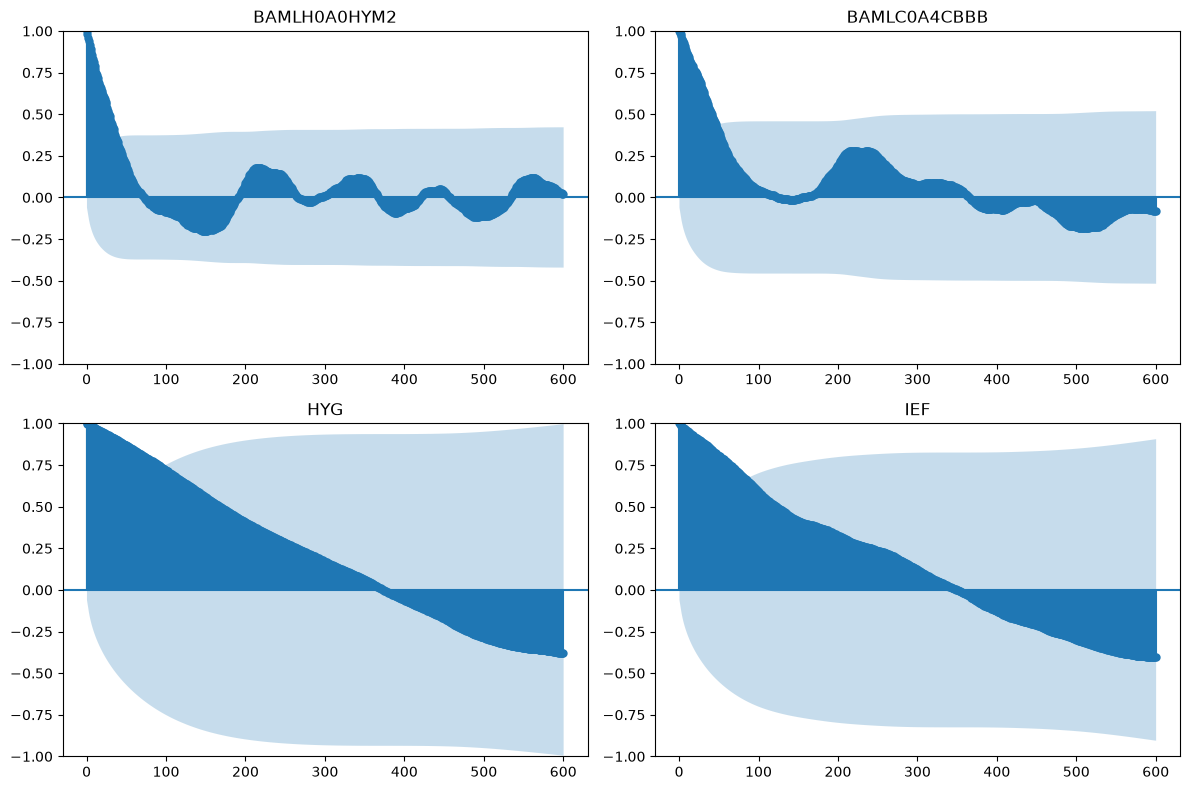

In [ ]:
candidate_features = [
    "BAMLH0A0HYM2",
    "BAMLC0A4CBBB",
    "HYG",
    "IEF",
]
# 2x2のサブプロットを作成して、各候補特徴量の自己相関を描画する
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
# 各候補特徴量の自己相関をプロット
for ax, feature in zip(axes, candidate_features):
    plot_acf(
        research_df[feature]
        .dropna(),
        lags=600,
        ax=ax
    )
    ax.set_title(feature)
plt.tight_layout()
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"14_Autocorrelation_of_Explanatory_Variables_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# ヒートマップの保存完了のメッセージを表示
print("saved:", output_path)
plt.show()

#### 15. Transform Explanatory Variables

価格系列とスプレッド系列を定常化する。

In [49]:
# 各候補特徴量の対数リターンおよびOAS変化を計算
research_df["HYG_LOG_RET"] = (np.log(research_df["HYG"]).diff())
# IEFの対数リターンを計算
research_df["IEF_LOG_RET"] = (np.log(research_df["IEF"]).diff())
# HYおよびBBBのOAS変化を計算
research_df["HY_OAS_CHANGE"] = (research_df["BAMLH0A0HYM2"].diff())
# BBBのOAS変化を計算
research_df["BBB_OAS_CHANGE"] = (research_df["BAMLC0A4CBBB"].diff())

#### 16. Autocorrelation After Transformation

前処理後に自己相関がどの程度減少したか確認する。

saved: /workspace/data/figures/16_Autocorrelation_After_Transformation_1950-01-01_2026-10-29.png


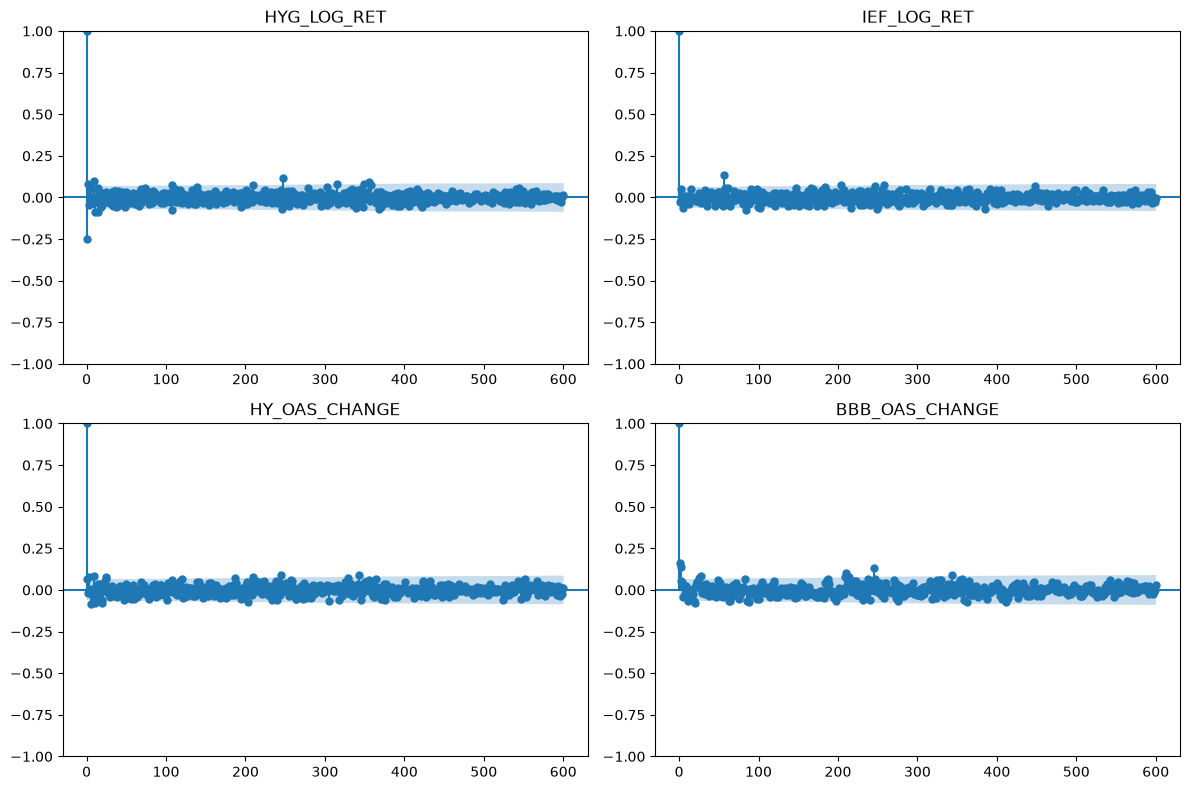

In [50]:
# 変換後の特徴量の自己相関をプロット
transformed_features = [
    "HYG_LOG_RET",
    "IEF_LOG_RET",
    "HY_OAS_CHANGE",
    "BBB_OAS_CHANGE",
]
# プロット用のサブプロットを作成
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
# サブプロットを1次元配列に変換
axes = axes.flatten()
# 各特徴量の自己相関をプロット
for ax, feature in zip(axes, transformed_features):
    # 対象特徴量の自己相関をプロット
    plot_acf(
        research_df[feature]
        .dropna(),
        lags=600,
        ax=ax
    )
    # サブプロットのタイトルを設定
    ax.set_title(feature)
# レイアウトを調整して表示
plt.tight_layout()
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"16_Autocorrelation_After_Transformation_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# ヒートマップの保存完了のメッセージを表示
print("saved:", output_path)
# プロットを表示
plt.show()

#### 17. Re-run Lag Correlation with Stationary Features

説明変数を定常化した後に再度ラグ相関分析を実施する。

目的:

- HYG, IEF の価格トレンドの影響を除去
- HY OAS, BBB OAS の長期レベルの影響を除去
- 先行して観測された周期性が説明変数の非定常性に起因するか検証する

In [51]:
# ラグごとの相関を計算 (自己相関の解析)
lags = np.arange(0, 1001, 20)
# 計算するラグの範囲を設定
stationary_features = [
    "HYG_LOG_RET",
    "IEF_LOG_RET",
    "HY_OAS_CHANGE",
    "BBB_OAS_CHANGE",
]
# 自己相関を計算する対象の特徴量を設定
results_stationary = []
# 
for feature in stationary_features:
    # 各特徴量ごとにラグごとの相関を計算
    for level in range(1, 7):
        # 対象のレベルに対応するカラム名を作成
        target_col = f"GSPC_D{level}"
        # 対象のカラムが存在しない場合はスキップ
        for lag in lags:
            # 対象のラグに対応するデータを作成
            tmp = pd.DataFrame(
                {
                    "x": research_df[feature],
                    "y": research_df[target_col]
                    .shift(-lag),
                }
            ).dropna()
            # データが十分でない場合はスキップ
            if len(tmp) < 500:
                continue
            # 相関を計算
            corr = tmp["x"].corr(
                tmp["y"]
            )
            # 計算結果を保存
            results_stationary.append(
                {
                    "feature": feature,
                    "target": target_col,
                    "lag": lag,
                    "corr": corr,
                    "abs_corr": abs(corr),
                    "n": len(tmp),
                }
            )

lag_corr_stationary_df = pd.DataFrame(results_stationary)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"17_Re_run_Lag_Correlation_with_Stationary_Features_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
lag_corr_stationary_df.to_csv(output_path)
print("saved:", output_path)
# 自己相関の結果を表示
lag_corr_stationary_df.head()

saved: /workspace/data/17_Re_run_Lag_Correlation_with_Stationary_Features_2026-10-29.csv


,feature,target,lag,corr,abs_corr,n
0,HYG_LOG_RET,GSPC_D1,0,0.086845,0.086845,1023
1,HYG_LOG_RET,GSPC_D1,20,0.013415,0.013415,1003
2,HYG_LOG_RET,GSPC_D1,40,-0.036590,0.036590,983
3,HYG_LOG_RET,GSPC_D1,60,-0.003151,0.003151,963
4,HYG_LOG_RET,GSPC_D1,80,0.062506,0.062506,943


#### 18. Peak Lag Detection After Stationarization

各説明変数について最大絶対相関を持つラグを抽出する。

In [53]:
# 自己相関のピーク相関を抽出
peak_corr_stationary_df = (
    lag_corr_stationary_df
    .sort_values(
        "abs_corr",
        ascending=False
    )
    .groupby(
        ["feature", "target"],
        as_index=False
    )
    .first()
)
# ピーク相関の結果を保存するためのディレクトリとファイルパスを設定
peak_corr_stationary_df = (
    peak_corr_stationary_df
    .sort_values(
        "abs_corr",
        ascending=False
    )
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"18_Peak_Lag_Detection_After_Stationarization_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
peak_corr_stationary_df.to_csv(output_path)
print("saved:", output_path)
# ピーク相関の結果を保存
peak_corr_stationary_df.head(30)

saved: /workspace/data/18_Peak_Lag_Detection_After_Stationarization_2026-10-29.csv


,feature,target,lag,corr,abs_corr,n
12,HY_OAS_CHANGE,GSPC_D1,0,-0.183536,0.183536,1023
3,BBB_OAS_CHANGE,GSPC_D4,0,0.183148,0.183148,1023
15,HY_OAS_CHANGE,GSPC_D4,0,0.173690,0.173690,1023
4,BBB_OAS_CHANGE,GSPC_D5,0,0.132445,0.132445,1023
2,BBB_OAS_CHANGE,GSPC_D3,0,0.119679,0.119679,1023
0,BBB_OAS_CHANGE,GSPC_D1,0,-0.116884,0.116884,1023
9,HYG_LOG_RET,GSPC_D4,0,-0.115841,0.115841,1023
14,HY_OAS_CHANGE,GSPC_D3,0,0.115718,0.115718,1023
19,IEF_LOG_RET,GSPC_D2,360,-0.111165,0.111165,663
5,BBB_OAS_CHANGE,GSPC_D6,0,0.107513,0.107513,1023


#### 19. Peak Correlation Heatmap

定常化後の最大相関を可視化。

saved: /workspace/data/figures/19_Peak_Correlation_Heatmap_1950-01-01_2026-10-29.png


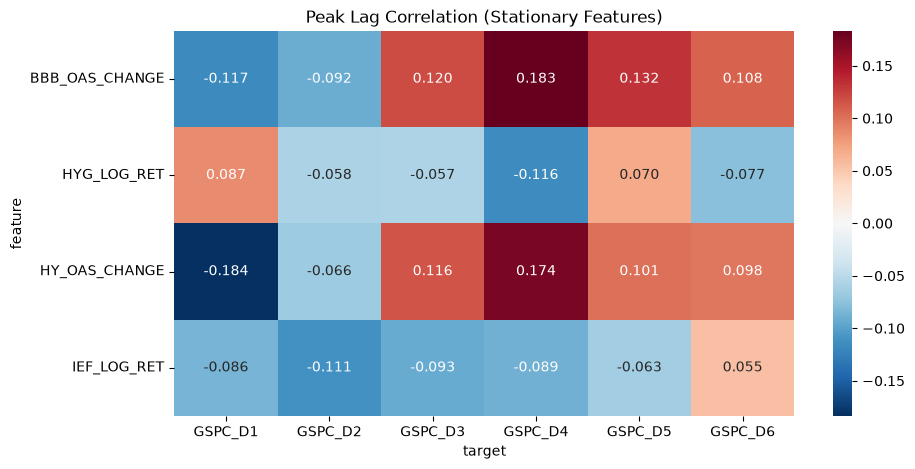

In [54]:
# ピーク相関のヒートマップを作成
heatmap_corr_stationary = (
    peak_corr_stationary_df
    .pivot(
        index="feature",
        columns="target",
        values="corr"
    )
)
plt.figure(figsize=(10, 5))
# ヒートマップを描画
sns.heatmap(
    heatmap_corr_stationary,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0
)
# ヒートマップのタイトルを設定
plt.title("Peak Lag Correlation (Stationary Features)")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"19_Peak_Correlation_Heatmap_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# ヒートマップの保存完了のメッセージを表示
print("saved:", output_path)
# プロットを表示
plt.show()

#### 20. Peak Lag Heatmap

最大相関となるラグを可視化。

saved: /workspace/data/figures/20_Peak_Lag_Heatmap_1950-01-01_2026-10-29.png


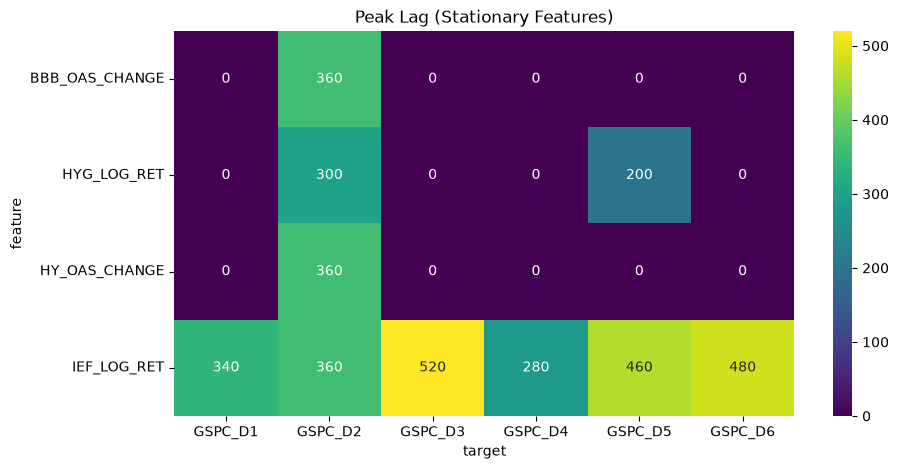

In [55]:
# ピークラグのヒートマップを作成
heatmap_lag_stationary = (
    peak_corr_stationary_df
    .pivot(
        index="feature",
        columns="target",
        values="lag"
    )
)
plt.figure(figsize=(10, 5))
sns.heatmap(
    heatmap_lag_stationary,
    annot=True,
    fmt=".0f",
    cmap="viridis"
)
plt.title("Peak Lag (Stationary Features)")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"20_Peak_Lag_Heatmap_{start}_{end}.png"
if output_path.exists():
    output_path.unlink()
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
print("saved:", output_path)
# ヒートマップを表示
plt.show()

#### 21. Detailed Lag Curve After Stationarization

長波長成分 GSPC_D6 に対するラグ相関曲線を確認する。

saved: /workspace/data/figures/21_Detailed_Lag_Curve_After_Stationarization_1950-01-01_2026-10-29.png


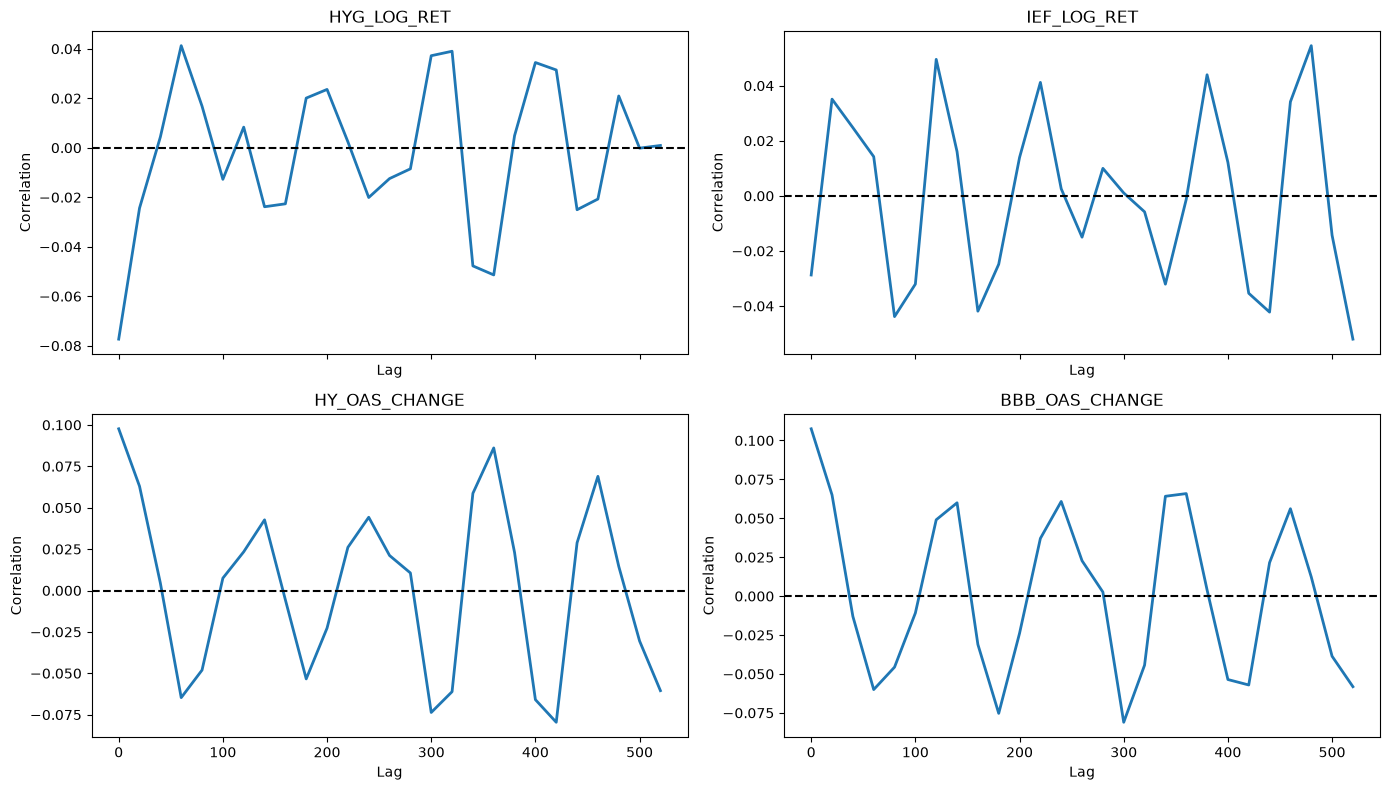

In [56]:
# ラグ相関のプロットを作成
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
axes = axes.flatten()
# 各特徴量に対してラグ相関をプロット
for ax, feature in zip(axes, stationary_features):
    # 対象の特徴量とターゲットに対応するラグ相関データを抽出
    tmp = lag_corr_stationary_df[
        (lag_corr_stationary_df["feature"] == feature)
        &
        (lag_corr_stationary_df["target"] == "GSPC_D6")
    ]
    ax.plot(tmp["lag"], tmp["corr"], linewidth=2)
    ax.axhline(0, color="black", linestyle="--")
    ax.set_title(feature)
    ax.set_ylabel("Correlation")
    ax.set_xlabel("Lag")
# プロットのレイアウトを調整
plt.tight_layout()
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"21_Detailed_Lag_Curve_After_Stationarization_{start}_{end}.png"
if output_path.exists():
    output_path.unlink()
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
print("saved:", output_path)
plt.show()

#### 22. Compare Before vs After Stationarization

定常化前後で最大相関がどの程度変化したか確認する。

In [57]:
# 
before = peak_corr_df.copy()
# 元のピーク相関データをコピーして保持
mapping = {
    "HYG_LOG_RET": "HYG",
    "IEF_LOG_RET": "IEF",
    "HY_OAS_CHANGE": "BAMLH0A0HYM2",
    "BBB_OAS_CHANGE": "BAMLC0A4CBBB",
}
after = peak_corr_stationary_df.copy()
# ラグ相関データをコピーして保持
after["original_feature"] = (
    after["feature"]
    .map(mapping)
)
# 元の特徴量名を保持する列を追加
compare_df = before.merge(
    after,
    left_on=["feature", "target"],
    right_on=["original_feature", "target"],
    suffixes=(
        "_before",
        "_after"
    )
)
# 元のデータとラグ相関データを結合して比較用のデータフレームを作成
compare_df = compare_df[
    [
        "feature_before",
        "target",
        "corr_before",
        "corr_after",
        "lag_before",
        "lag_after",
    ]
]
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"22_Compare_Before_vs_After_Stationarization_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
compare_df.to_csv(output_path)
print("saved:", output_path)
# 比較用データフレームの先頭30行を表示
compare_df.head(30)

saved: /workspace/data/22_Compare_Before_vs_After_Stationarization_2026-10-29.csv


,feature_before,target,corr_before,corr_after,lag_before,lag_after
0,BAMLH0A0HYM2,GSPC_D6,-0.326213,0.097651,380,0
1,BAMLC0A4CBBB,GSPC_D6,-0.230239,0.107513,380,0
2,IEF,GSPC_D6,0.186317,0.054526,460,480
3,HYG,GSPC_D6,0.168946,-0.077335,460,0
4,BAMLH0A0HYM2,GSPC_D5,-0.148209,0.100762,480,0
5,BAMLC0A4CBBB,GSPC_D5,-0.125195,0.132445,480,0
6,BAMLH0A0HYM2,GSPC_D4,-0.098593,0.173690,480,0
7,BAMLC0A4CBBB,GSPC_D4,-0.092686,0.183148,480,0
8,IEF,GSPC_D5,0.085581,-0.063338,460,460
9,HYG,GSPC_D5,0.052432,0.069673,480,200


# Credit Market vs S&P500 Multi-Scale Analysis

## 検証目的

信用市場および債券市場の指標が、S&P500のどの時間スケールの変動と関係を持つかを調査する。

特に、

- HY OAS（BAMLH0A0HYM2）
- BBB OAS（BAMLC0A4CBBB）
- HYG
- IEF

が、S&P500対数リターンのWavelet成分（D1～D6）に対して先行性を持つか検証した。

---

## 検証手順

### Phase1: Wavelet分解

1. S&P500価格を対数リターンへ変換
2. SWT（Stationary Wavelet Transform）を適用
3. D1～D6のWavelet成分を生成

### Phase2: Lag Correlation Analysis

各説明変数について

```text
corr(
    X(t),
    GSPC_Dk(t + lag)
)
```

を計算し、

- Lag = 0～520営業日
- Wavelet Scale = D1～D6

の相関構造を可視化した。

### Phase3: 周期性の原因分析

以下を実施した。

- GSPC_D1～D6 の自己相関（ACF）
- GSPC_D1～D6 のFFT
- 説明変数の自己相関（ACF）
- 説明変数の定常化

定常化は以下を使用した。

```text
HYG_LOG_RET
IEF_LOG_RET
HY_OAS_CHANGE
BBB_OAS_CHANGE
```

その後、ラグ相関分析を再実施した。

---

## 検証結果

初回分析では、

```text
HY OAS
BBB OAS
HYG
IEF
```

の全てで類似した周期的ラグ構造が観測された。

しかし追加検証により、

- GSPC_D5/D6は強い周期構造を持つ
- 説明変数も強い自己相関を持つ
- 非定常系列同士のラグ相関により擬似的な周期構造が発生していた

ことが判明した。

説明変数を定常化すると、

```text
380営業日先行
440営業日先行
480営業日先行
```

などの強いラグ構造は大幅に弱まり、多くが消失した。

一方で、

```text
HY_OAS_CHANGE
BBB_OAS_CHANGE
```

とWavelet成分の相関は残存し、

```text
|corr| ≒ 0.10～0.18
```

程度の弱いが一貫した関係が確認された。

---

## 現時点の結論

現時点では、

```text
信用市場が1年以上先の株価を予測する
```

という仮説を支持する証拠は得られていない。

一方で、

```text
信用スプレッドの変化率
↓
S&P500のマルチスケール変動
```

には一定の関係が存在する可能性が確認された。

今後はラグ構造探索よりも、

- Decile Analysis
- Mutual Information
- Spearman Correlation
- 非線形関係の検証

を優先することが望ましい。